# AH2179 Traffic project — 02: Models, evaluation and diagnostics

**Task:** predict the flow (veh/h) at one portal **15 min ahead**, for target times 07:30–08:30 (local time), from the features
built in `01_cleaning_EDA_features.ipynb`.

| Split | Used for |
|---|---|
| train (2021-06-01 – 11-14) | fitting, hyper-parameter tuning with **blocked time-series CV** (folds = blocks of whole days) |
| val (2021-11-15 – 12-31) | model selection / early stopping |
| evaluation (2022) | comparing the refitted models (fitted on train + val) |
| final_evaluation (2022) | **run once** for the selected model (`RUN_FINAL = True`) |

Models: two baselines (persistence, historical average), **ridge regression** (linear), **XGBoost** (main model, takes NaN as
is) and a **Keras MLP** (deep model, needs imputed + scaled inputs).
Rows whose *target* is missing are never imputed — they are excluded from fitting and scoring, and the scored row count is reported.
Rows with missing *inputs* are always predicted.

In [1]:
import warnings, json, time; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, ParameterSampler
import xgboost as xgb
import traffic_prep as tp

TARGET = "q_p55620"            # target portal flow; change to e.g. "q_p56780" (avoid q_p57820: large 2022 outage)
Y = f"y_{TARGET}"
RUN_FINAL = False              # set True ONCE, after the model choice is frozen
SEED = 42

OUT = Path("../processed"); FIG = Path("../figures"); MOD = Path("../models"); RES = Path("../results")
for p in (FIG, MOD, RES): p.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9})
def save(fig, name): fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150)

D = {n: pd.read_csv(OUT / f"features_{n}.csv", index_col=0, parse_dates=True)
     for n in ["train", "val", "evaluation", "final_evaluation"]}
X_COLS = [c for c in D["train"].columns if not c.startswith("y_")]
for n, d in D.items():
    print(f"{n:17s} rows {len(d):5d} | target missing {d[Y].isna().sum():3d} | rows with any missing input {d[X_COLS].isna().any(axis=1).sum():4d}")
print("n features:", len(X_COLS))

train             rows  2171 | target missing 117 | rows with any missing input  150
val               rows   611 | target missing   0 | rows with any missing input    0
evaluation        rows  1170 | target missing  26 | rows with any missing input  243
final_evaluation  rows  1183 | target missing  26 | rows with any missing input  364
n features: 132


## 1. Evaluation helpers and baselines

In [2]:
def metrics(y, yhat):
    m = y.notna()
    assert yhat[m].notna().all(), "model must predict every row that has a target"
    e = yhat[m] - y[m]
    return {"n": int(m.sum()), "RMSE": np.sqrt((e ** 2).mean()), "MAE": e.abs().mean(),
            "MAPE_%": (e.abs() / y[m]).mean() * 100, "bias": e.mean(),
            "R2": 1 - (e ** 2).sum() / ((y[m] - y[m].mean()) ** 2).sum()}

def table(preds, split):
    y = D[split][Y]
    return pd.DataFrame({k: metrics(y, v) for k, v in preds.items()}).T.round(3).sort_values("RMSE")

def baselines(d):
    hist = d[f"hist_{TARGET}"]
    return {"persistence": d[f"{TARGET}_lag0"].fillna(hist),   # fallback to hist when the current value is missing
            "historical average": hist}

def day_block_cv(index, n_splits=5):
    '''Expanding-window CV over whole days: never trains on the future, never splits a morning.'''
    days = np.array(sorted(index.normalize().unique()))
    norm = index.normalize()
    for tr_d, te_d in TimeSeriesSplit(n_splits).split(days):
        yield np.where(norm.isin(days[tr_d]))[0], np.where(norm.isin(days[te_d]))[0]

pred = {s: dict(baselines(D[s])) for s in D}
table(pred["val"], "val")

,n,RMSE,MAE,MAPE_%,bias,R2
persistence,611.0,354.523,253.766,12.529,-2.496,0.909
historical average,611.0,532.689,387.822,25.124,79.452,0.795


## 2. Ridge regression (linear model)
Inputs: missing values filled with `tp.FeatureImputer` (causal, fitted on train) + missing flags, then z-scored with training statistics.
The regularisation strength is chosen by blocked time-series CV.

In [3]:
tr = D["train"][D["train"][Y].notna()]                      # never fit on a missing target
imp = tp.FeatureImputer().fit(tr[X_COLS])
def prep_dense(d, imp=imp):
    return imp.transform(d[X_COLS])
Xtr_d = prep_dense(tr); DENSE_COLS = list(Xtr_d.columns)
sc = StandardScaler().fit(Xtr_d)
Z = lambda d: sc.transform(prep_dense(d)[DENSE_COLS])

ridge = RidgeCV(alphas=np.logspace(-2, 4, 25), cv=list(day_block_cv(tr.index)), scoring="neg_root_mean_squared_error")
ridge.fit(sc.transform(Xtr_d), tr[Y])
print("chosen alpha:", ridge.alpha_)
for s in D: pred[s]["ridge"] = pd.Series(ridge.predict(Z(D[s])), index=D[s].index)
table(pred["val"], "val")

chosen alpha: 0.31622776601683794


,n,RMSE,MAE,MAPE_%,bias,R2
ridge,611.0,260.744,191.215,11.757,51.063,0.951
persistence,611.0,354.523,253.766,12.529,-2.496,0.909
historical average,611.0,532.689,387.822,25.124,79.452,0.795


## 3. XGBoost (main model)
* Missing inputs are passed as NaN — each split learns a default direction for them.
* Hyper-parameters: random search, scored with **blocked time-series CV** on the train split (early stopping inside each fold).
* The number of trees is then fixed by early stopping on the validation split.

In [4]:
space = {"max_depth": [3, 4, 5, 6], "min_child_weight": [1, 3, 5, 10], "subsample": [0.6, 0.8, 1.0],
         "colsample_bytree": [0.3, 0.5, 0.7, 1.0], "reg_lambda": [1, 5, 10, 30], "gamma": [0, 1, 5]}
N_TRIALS = 15                  # raise to 40–60 on your own machine for a better search
base_params = dict(n_estimators=2000, learning_rate=0.03, tree_method="hist", objective="reg:squarederror",
                   early_stopping_rounds=100, n_jobs=4, random_state=SEED)
t0 = time.time(); trials = []
folds = list(day_block_cv(tr.index, n_splits=4))
for params in ParameterSampler(space, N_TRIALS, random_state=SEED):
    rmses, iters = [], []
    for a, b in folds:
        m = xgb.XGBRegressor(**base_params, **params)
        m.fit(tr[X_COLS].iloc[a], tr[Y].iloc[a], eval_set=[(tr[X_COLS].iloc[b], tr[Y].iloc[b])], verbose=False)
        rmses.append(m.best_score); iters.append(m.best_iteration)
    trials.append({**params, "cv_rmse": np.mean(rmses), "cv_rmse_sd": np.std(rmses), "iters": int(np.mean(iters))})
trials = pd.DataFrame(trials).sort_values("cv_rmse")
print(f"search took {time.time() - t0:.0f} s")
trials.head(5).round(2)

search took 53 s


,subsample,reg_lambda,min_child_weight,max_depth,gamma,colsample_bytree,cv_rmse,cv_rmse_sd,iters
0,1.0,10,10,4,1,0.5,279.27,69.49,252
6,0.8,30,5,4,5,0.3,279.47,66.09,371
10,1.0,30,3,3,5,1.0,280.67,67.79,346
11,0.8,30,5,5,0,0.3,283.34,67.30,392
1,0.8,30,10,5,0,0.7,286.42,75.40,333


best params: {'max_depth': 4, 'min_child_weight': 10, 'subsample': 1.0, 'colsample_bytree': 0.5, 'reg_lambda': 10.0, 'gamma': 1.0} | trees: 264


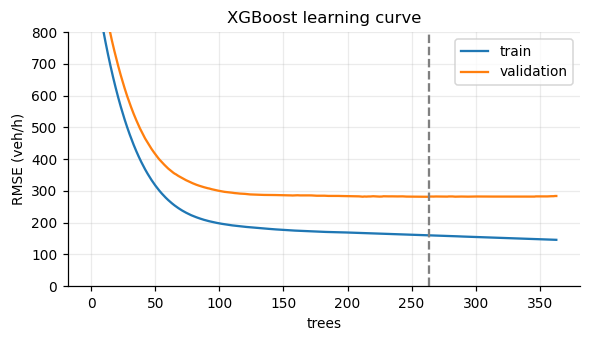

,n,RMSE,MAE,MAPE_%,bias,R2
ridge,611.0,260.744,191.215,11.757,51.063,0.951
xgboost,611.0,281.533,211.214,13.993,96.511,0.943
persistence,611.0,354.523,253.766,12.529,-2.496,0.909
historical average,611.0,532.689,387.822,25.124,79.452,0.795


In [5]:
best = trials.iloc[0][list(space)].to_dict()
best = {k: (int(v) if k in ("max_depth", "min_child_weight") else float(v)) for k, v in best.items()}
va = D["val"][D["val"][Y].notna()]
xgb_model = xgb.XGBRegressor(**base_params, **best, eval_metric="rmse")
xgb_model.fit(tr[X_COLS], tr[Y], eval_set=[(tr[X_COLS], tr[Y]), (va[X_COLS], va[Y])], verbose=False)
N_TREES = xgb_model.best_iteration + 1
print("best params:", best, "| trees:", N_TREES)

ev = xgb_model.evals_result()
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(ev["validation_0"]["rmse"], label="train"); ax.plot(ev["validation_1"]["rmse"], label="validation")
ax.axvline(N_TREES, color="grey", ls="--"); ax.set(xlabel="trees", ylabel="RMSE (veh/h)", title="XGBoost learning curve", ylim=(0, 800)); ax.legend()
save(fig, "07_xgb_learning_curve"); plt.show()

for s in D: pred[s]["xgboost"] = pd.Series(xgb_model.predict(D[s][X_COLS], iteration_range=(0, N_TREES)), index=D[s].index)
table(pred["val"], "val")

## 4. Keras MLP (deep model)
Same imputed + scaled inputs as ridge. Target divided by 1 000 for stable training. Early stopping on validation keeps the best epoch.

2026-09-23 11:34:52.414880: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2 Max
2026-09-23 11:34:52.414929: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 32.00 GB
2026-09-23 11:34:52.414934: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 12.48 GB
2026-09-23 11:34:52.414978: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-09-23 11:34:52.414991: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
2026-09-23 11:34:53.985490: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


best epoch: 40


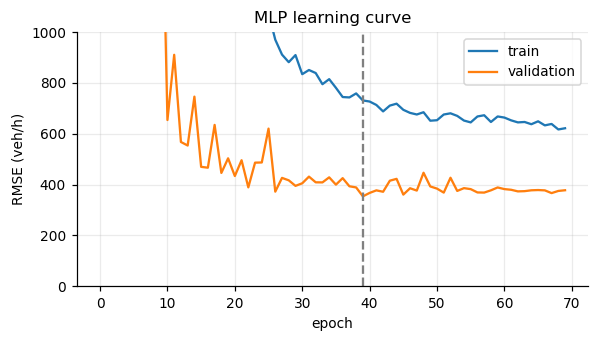

,n,RMSE,MAE,MAPE_%,bias,R2
ridge,611.0,260.744,191.215,11.757,51.063,0.951
xgboost,611.0,281.533,211.214,13.993,96.511,0.943
mlp,611.0,353.562,270.457,18.562,53.599,0.910
persistence,611.0,354.523,253.766,12.529,-2.496,0.909
historical average,611.0,532.689,387.822,25.124,79.452,0.795


In [6]:
import tensorflow as tf
from tensorflow import keras
keras.utils.set_random_seed(SEED)
YS = 1000.0

def make_mlp(n_in):
    m = keras.Sequential([keras.Input((n_in,)),
                          keras.layers.Dense(128, activation="relu"), keras.layers.Dropout(0.2),
                          keras.layers.Dense(64, activation="relu"), keras.layers.Dropout(0.2),
                          keras.layers.Dense(1)])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
    return m

Ztr, Zva = Z(tr), Z(va)
mlp = make_mlp(Ztr.shape[1])
cb = [keras.callbacks.EarlyStopping(patience=30, restore_best_weights=True),
      keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=10)]
hist = mlp.fit(Ztr, tr[Y] / YS, validation_data=(Zva, va[Y] / YS), epochs=400, batch_size=64, callbacks=cb, verbose=0)
BEST_EPOCH = int(np.argmin(hist.history["val_loss"])) + 1
print("best epoch:", BEST_EPOCH)

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(np.sqrt(hist.history["loss"]) * YS, label="train"); ax.plot(np.sqrt(hist.history["val_loss"]) * YS, label="validation")
ax.axvline(BEST_EPOCH - 1, color="grey", ls="--"); ax.set(xlabel="epoch", ylabel="RMSE (veh/h)", title="MLP learning curve", ylim=(0, 1000)); ax.legend()
save(fig, "07_mlp_learning_curve"); plt.show()

for s in D: pred[s]["mlp"] = pd.Series(mlp.predict(Z(D[s]), verbose=0).ravel() * YS, index=D[s].index)
res_val = table(pred["val"], "val"); res_val

## 5. Model selection on validation → refit on all 2021 data → 2022 evaluation
Hyper-parameters, tree count and epoch count are frozen from the steps above. Each model is refitted on train + val
(all of 2021), because the most recent weeks are the most informative for 2022, and then scored on the evaluation file.

In [7]:
full = pd.concat([D["train"], D["val"]]); full = full[full[Y].notna()]
imp_f = tp.FeatureImputer().fit(full[X_COLS])
dense_f = imp_f.transform(full[X_COLS]); sc_f = StandardScaler().fit(dense_f[DENSE_COLS])
Zf = lambda d: sc_f.transform(imp_f.transform(d[X_COLS])[DENSE_COLS])

ridge_f = RidgeCV(alphas=[ridge.alpha_]).fit(sc_f.transform(dense_f[DENSE_COLS]), full[Y])
xgb_f = xgb.XGBRegressor(**{**base_params, "early_stopping_rounds": None, "n_estimators": int(N_TREES * 1.15)}, **best)
xgb_f.fit(full[X_COLS], full[Y], verbose=False)
keras.utils.set_random_seed(SEED)
mlp_f = make_mlp(len(DENSE_COLS))
mlp_f.fit(Zf(full), full[Y] / YS, epochs=int(BEST_EPOCH * 1.15), batch_size=64, verbose=0)

final_models = {"ridge": lambda d: ridge_f.predict(Zf(d)),
                "xgboost": lambda d: xgb_f.predict(d[X_COLS]),
                "mlp": lambda d: mlp_f.predict(Zf(d), verbose=0).ravel() * YS}
for s in ["evaluation", "final_evaluation"]:
    for k, f in final_models.items(): pred[s][k] = pd.Series(f(D[s]), index=D[s].index)

res_eval = table(pred["evaluation"], "evaluation")
res_val.to_csv(RES / f"val_{TARGET}.csv"); res_eval.to_csv(RES / f"evaluation_{TARGET}.csv")
res_eval

,n,RMSE,MAE,MAPE_%,bias,R2
xgboost,1144.0,284.480,207.809,10.847,28.832,0.939
ridge,1144.0,298.321,220.320,11.585,8.897,0.933
persistence,1144.0,402.138,290.540,13.523,-11.653,0.878
historical average,1144.0,436.067,341.155,20.758,-52.460,0.856
mlp,1144.0,438.390,320.674,18.354,-74.496,0.855


In [8]:
# save models + preprocessing (the .keras file is the required deliverable)
xgb_f.save_model(MOD / f"xgb_{TARGET}.json")
mlp_f.save(MOD / f"mlp_{TARGET}.keras")
joblib.dump({"ridge": ridge_f, "imputer": imp_f, "scaler": sc_f, "dense_cols": DENSE_COLS, "x_cols": X_COLS,
             "y_scale": YS, "xgb_params": best, "n_trees": int(N_TREES * 1.15)}, MOD / f"prep_and_ridge_{TARGET}.joblib")
sorted(p.name for p in MOD.iterdir())

['mlp_aug_q_p55620.keras',
 'mlp_q_p55620.keras',
 'prep_and_ridge_q_p55620.joblib',
 'ridge_aug_q_p55620.joblib',
 'xgb_aug_q_p55620.json',
 'xgb_q_p55620.json']

## 6. Diagnostics (evaluation file)

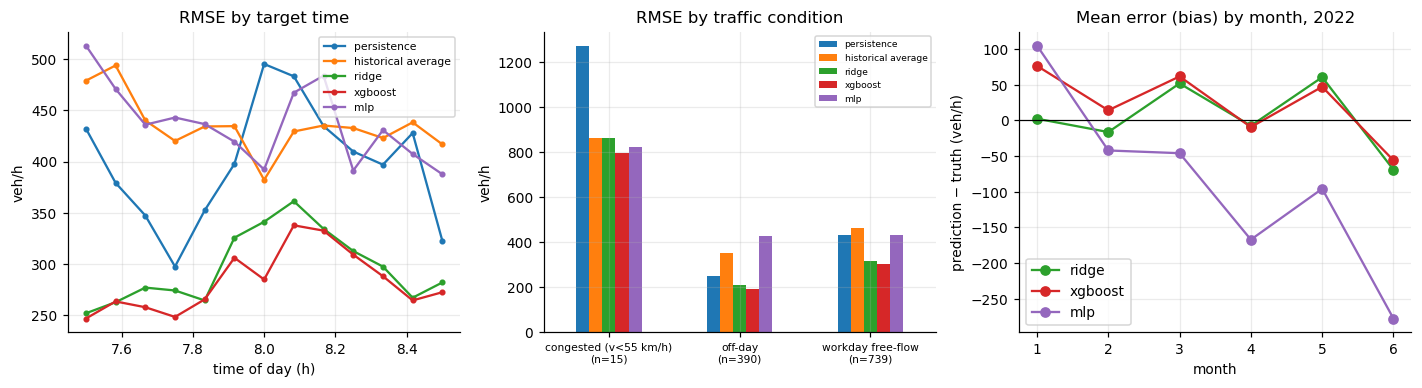

,persistence,historical average,ridge,xgboost,mlp
congested (v<55 km/h),1272.0,864.0,864.0,798.0,825.0
off-day,248.0,354.0,212.0,192.0,428.0
workday free-flow,430.0,462.0,314.0,305.0,432.0


In [9]:
S = "evaluation"; d = D[S]; y = d[Y]; ok = y.notna()
models = ["persistence", "historical average", "ridge", "xgboost", "mlp"]
COL = dict(zip(models, ["C0", "C1", "C2", "C3", "C4"]))   # one colour per model in every plot
tod = d["tod_target_min"] / 60
spd = d[f"v_{TARGET[2:]}_lag0"]
cond = pd.Series(np.select([d.is_offday == 1, spd < 55], ["off-day", "congested (v<55 km/h)"], "workday free-flow"), index=d.index)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for k in models:
    e = (pred[S][k] - y)[ok]
    ax[0].plot(e.groupby(tod[ok]).apply(lambda s: np.sqrt((s ** 2).mean())), "o-", ms=3, color=COL[k], label=k)
ax[0].set(title="RMSE by target time", xlabel="time of day (h)", ylabel="veh/h"); ax[0].legend(fontsize=7)
g = pd.DataFrame({k: (pred[S][k] - y)[ok].groupby(cond[ok]).apply(lambda s: np.sqrt((s ** 2).mean())) for k in models})
g.plot.bar(ax=ax[1], rot=0, color=[COL[k] for k in g.columns]); ax[1].set(title="RMSE by traffic condition", ylabel="veh/h", xlabel="")
ax[1].set_xticklabels([f"{i}\n(n={int((cond[ok] == i).sum())})" for i in g.index], fontsize=7); ax[1].legend(fontsize=6)
mon = pd.DataFrame({k: (pred[S][k] - y)[ok].groupby(d.index[ok].month).mean() for k in ["ridge", "xgboost", "mlp"]})
mon.plot(ax=ax[2], marker="o", color=[COL[k] for k in mon.columns]); ax[2].axhline(0, color="k", lw=.8)
ax[2].set(title="Mean error (bias) by month, 2022", xlabel="month", ylabel="prediction − truth (veh/h)")
fig.tight_layout(); save(fig, "08_error_breakdown"); plt.show()
g.round(0)

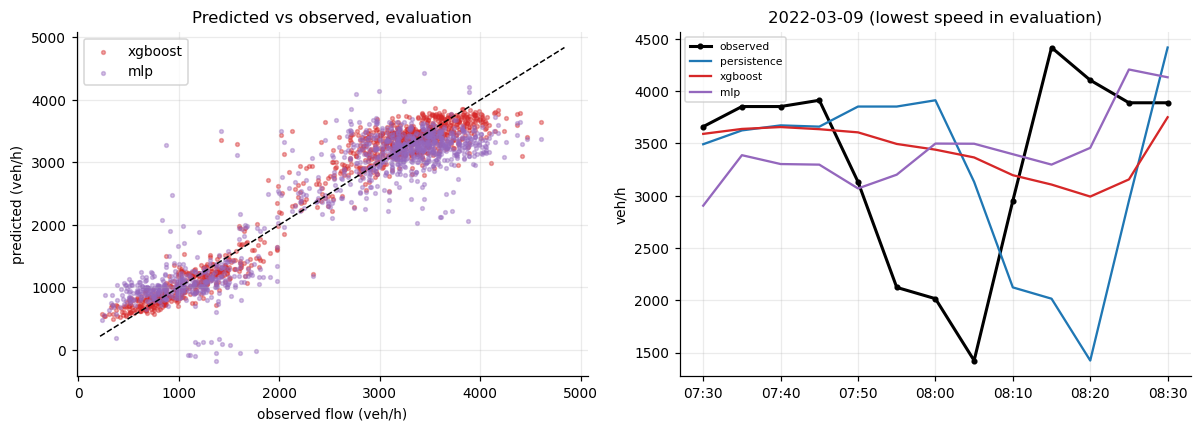

In [10]:
best_name = res_eval.index[0]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k, c in [("xgboost", COL["xgboost"]), ("mlp", COL["mlp"])]:
    ax[0].scatter(y[ok], pred[S][k][ok], s=6, alpha=.4, color=c, label=k)
lim = [y.min() * .9, y.max() * 1.05]; ax[0].plot(lim, lim, "k--", lw=1)
ax[0].set(xlabel="observed flow (veh/h)", ylabel="predicted (veh/h)", title="Predicted vs observed, evaluation"); ax[0].legend()
# the most congested evaluation day
day = spd.groupby(spd.index.normalize()).min().idxmin()
dd = d.index.normalize() == day
t_target = d.index[dd] + pd.Timedelta(minutes=15)
ax[1].plot(t_target, y[dd], "k-o", ms=3, lw=2, label="observed")
for k in ["persistence", "xgboost", "mlp"]: ax[1].plot(t_target, pred[S][k][dd], lw=1.5, color=COL[k], label=k)
ax[1].set(title=f"{day.date()} (lowest speed in evaluation)", ylabel="veh/h"); ax[1].legend(fontsize=7)
ax[1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M"))
fig.tight_layout(); save(fig, "08_pred_vs_obs"); plt.show()

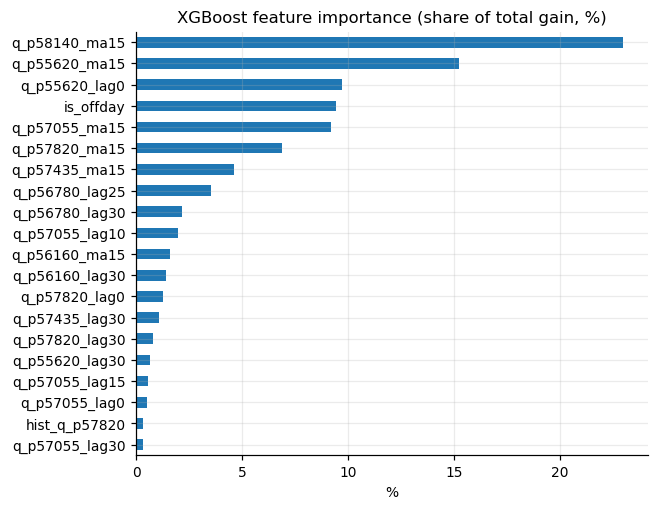

In [11]:
imp_gain = pd.Series(xgb_f.get_booster().get_score(importance_type="gain")).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(6, 5))
(imp_gain.head(20)[::-1] / imp_gain.sum() * 100).plot.barh(ax=ax)
ax.set(title="XGBoost feature importance (share of total gain, %)", xlabel="%")
save(fig, "08_xgb_importance"); plt.show()

### Robustness: what happens when sensors fail?
Inputs in the evaluation file are deliberately removed (set to NaN) and the models predict again — XGBoost with NaN,
ridge / MLP through the same imputer as in production. This simulates the outages seen in the data.

In [12]:
rng = np.random.default_rng(SEED)
own = [c for c in X_COLS if c.startswith((f"q_{TARGET[2:]}", f"v_{TARGET[2:]}"))] + [c for c in X_COLS if TARGET[2:] in c and c.startswith("dv_")]
tgt_km = [k for k, v in tp.PORTAL_COL.items() if v == TARGET[2:]][0]
upstream = [c for c in X_COLS if any(c.startswith((f"q_{tp.PORTAL_COL[k]}", f"v_{tp.PORTAL_COL[k]}"))
                                     for k in tp.PORTALS_DOWNSTREAM if k > tgt_km)]
portal_feats = [c for c in X_COLS if c.startswith(("q_p", "v_p", "dv_")) and not c.endswith("_filled")]
own = [c for c in own if not c.endswith("_filled")]; upstream = [c for c in upstream if not c.endswith("_filled")]
def rand_mask(df, frac=0.2):
    df = df.copy(); M = rng.random((len(df), len(portal_feats))) < frac
    df[portal_feats] = df[portal_feats].mask(M); return df
scen = {"no failure": lambda df: df,
        "target portal down": lambda df: df.assign(**{c: np.nan for c in own}),
        "all upstream portals down": lambda df: df.assign(**{c: np.nan for c in upstream}),
        "random 20 % of sensor values missing": rand_mask}
rob = {}
for name, f in scen.items():
    dm = f(d)
    rob[name] = {k: metrics(y, pd.Series(fn(dm), index=d.index))["RMSE"] for k, fn in final_models.items()}
rob = pd.DataFrame(rob).T
rob["historical average"] = metrics(y, pred[S]["historical average"])["RMSE"]
rob.round(0)

,ridge,xgboost,mlp,historical average
no failure,298.0,284.0,438.0,436.0
target portal down,313.0,648.0,467.0,436.0
all upstream portals down,309.0,644.0,1095.0,436.0
random 20 % of sensor values missing,305.0,416.0,1277.0,436.0


**How to read this:** a model is only useful in operation if a sensor failure makes it degrade *gracefully*, i.e. it stays
better than the historical average. XGBoost handles NaN technically, but it only learns good default directions for
missing-value patterns it saw in training — and whole-portal outages are rare there. If it degrades badly, the fix is
**masking augmentation**: add copies of the training rows with random portals set to NaN (and the imputer applied for ridge/MLP)
so the models learn to fall back on the remaining sensors.

## 6b. Masking augmentation — teaching the models to cope with sensor failures
Each training row is kept and **2 extra copies** are added in which sensor inputs are blanked (`tp.mask_augment`):

* a per-row failure rate is drawn from U(0, 0.9) and each portal is switched off with that rate (whole-portal outage);
* independently, single values are dropped with a rate drawn from U(0, 0.3).

The failure patterns are *generic* (random portals, random severity), not a copy of the test scenarios, so the robustness
test is still an honest test. Hyper-parameters are kept from section 3–4; the tree / epoch counts are re-chosen by early stopping
on the **clean** validation set, then everything is refitted on augmented train + val, as before.

In [13]:
t0 = time.time()
N_COPIES = 2
tr_aug = tp.mask_augment(tr, X_COLS, n_copies=N_COPIES, seed=1)
full_aug = tp.mask_augment(full, X_COLS, n_copies=N_COPIES, seed=2)
print(f"train rows {len(tr)} -> {len(tr_aug)} | share of missing inputs: "
      f"{tr[X_COLS].isna().mean().mean():.1%} -> {tr_aug[X_COLS].isna().mean().mean():.1%}")

# --- XGBoost: same hyper-parameters, tree count by early stopping on clean validation
m = xgb.XGBRegressor(**base_params, **best, eval_metric="rmse")
m.fit(tr_aug[X_COLS], tr_aug[Y], eval_set=[(va[X_COLS], va[Y])], verbose=False)
N_TREES_AUG = m.best_iteration + 1
xgb_aug = xgb.XGBRegressor(**{**base_params, "early_stopping_rounds": None, "n_estimators": int(N_TREES_AUG * 1.15)}, **best)
xgb_aug.fit(full_aug[X_COLS], full_aug[Y], verbose=False)

# --- ridge + MLP: imputer and scaler stay the ones fitted on clean 2021 data (imp_f, sc_f)
ridge_aug = RidgeCV(alphas=[ridge.alpha_]).fit(Zf(full_aug), full_aug[Y])

keras.utils.set_random_seed(SEED)
m = make_mlp(len(DENSE_COLS))
h = m.fit(Zf(tr_aug), tr_aug[Y] / YS, validation_data=(Zf(va), va[Y] / YS), epochs=300, batch_size=128, verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True),
                     keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=8)])
BEST_EPOCH_AUG = int(np.argmin(h.history["val_loss"])) + 1
keras.utils.set_random_seed(SEED)
mlp_aug = make_mlp(len(DENSE_COLS))
mlp_aug.fit(Zf(full_aug), full_aug[Y] / YS, epochs=int(BEST_EPOCH_AUG * 1.15), batch_size=128, verbose=0)
print(f"trees {N_TREES} -> {N_TREES_AUG} | MLP epochs {BEST_EPOCH} -> {BEST_EPOCH_AUG} | {time.time() - t0:.0f} s")

aug_models = {"ridge + aug": lambda d: ridge_aug.predict(Zf(d)),
              "xgboost + aug": lambda d: xgb_aug.predict(d[X_COLS]),
              "mlp + aug": lambda d: mlp_aug.predict(Zf(d), verbose=0).ravel() * YS}
for s in ["evaluation", "final_evaluation"]:
    for k, f in aug_models.items(): pred[s][k] = pd.Series(f(D[s]), index=D[s].index)
table(pred["evaluation"], "evaluation")

train rows 2054 -> 6162 | share of missing inputs: 0.4% -> 30.6%
trees 264 -> 485 | MLP epochs 40 -> 90 | 156 s


,n,RMSE,MAE,MAPE_%,bias,R2
xgboost,1144.0,284.480,207.809,10.847,28.832,0.939
xgboost + aug,1144.0,289.546,213.341,11.029,22.253,0.937
ridge,1144.0,298.321,220.320,11.585,8.897,0.933
ridge + aug,1144.0,301.908,225.105,12.239,-0.453,0.931
persistence,1144.0,402.138,290.540,13.523,-11.653,0.878
historical average,1144.0,436.067,341.155,20.758,-52.460,0.856
mlp,1144.0,438.390,320.674,18.354,-74.496,0.855
mlp + aug,1144.0,595.603,511.052,33.119,-3.335,0.732


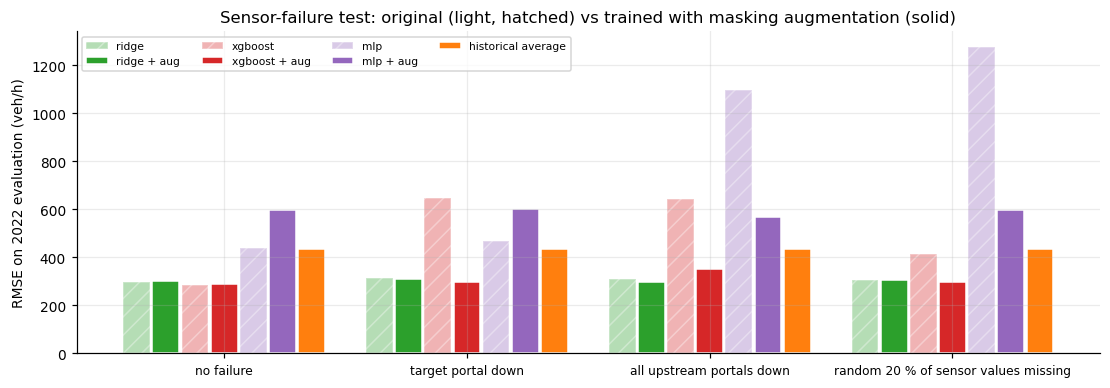

,ridge,ridge + aug,xgboost,xgboost + aug,mlp,mlp + aug,historical average
no failure,298.0,302.0,284.0,290.0,438.0,596.0,436.0
target portal down,313.0,309.0,648.0,297.0,467.0,601.0,436.0
all upstream portals down,309.0,299.0,644.0,351.0,1095.0,570.0,436.0
random 20 % of sensor values missing,305.0,304.0,416.0,295.0,1277.0,596.0,436.0


In [14]:
# robustness test again: same scenarios, same random mask for every model
all_models = {**final_models, **aug_models}
masked = {}
for name, f in scen.items():
    rng = np.random.default_rng(SEED)            # identical random mask for all models
    masked[name] = f(d)
rob2 = pd.DataFrame({name: {k: metrics(y, pd.Series(fn(dm), index=d.index))["RMSE"] for k, fn in all_models.items()}
                     for name, dm in masked.items()}).T
rob2["historical average"] = metrics(y, pred[S]["historical average"])["RMSE"]
order = ["ridge", "ridge + aug", "xgboost", "xgboost + aug", "mlp", "mlp + aug", "historical average"]
rob2 = rob2[order]; rob2.to_csv(RES / f"robustness_{TARGET}.csv")

fig, ax = plt.subplots(figsize=(12, 3.8))
xs = np.arange(len(rob2)); w = 0.12
for i, k in enumerate(order):
    base_col = COL.get(k.replace(" + aug", ""), "0.5")
    ax.bar(xs + (i - 3) * w, rob2[k], w * .92, color=base_col, alpha=1 if ("aug" in k or k == "historical average") else .35,
           hatch="" if "aug" in k or k == "historical average" else "//", edgecolor="white", label=k)
ax.set_xticks(xs, rob2.index, fontsize=8); ax.set(ylabel="RMSE on 2022 evaluation (veh/h)",
      title="Sensor-failure test: original (light, hatched) vs trained with masking augmentation (solid)")
ax.legend(fontsize=7, ncol=4); save(fig, "08_robustness_augmentation"); plt.show()
rob2.round(0)

In [15]:
xgb_aug.save_model(MOD / f"xgb_aug_{TARGET}.json")
mlp_aug.save(MOD / f"mlp_aug_{TARGET}.keras")
joblib.dump({"ridge_aug": ridge_aug, "n_trees_aug": int(N_TREES_AUG * 1.15), "mlp_epochs_aug": int(BEST_EPOCH_AUG * 1.15)},
            MOD / f"ridge_aug_{TARGET}.joblib")
res_eval_all = table(pred["evaluation"], "evaluation"); res_eval_all.to_csv(RES / f"evaluation_{TARGET}.csv")
res_eval_all

,n,RMSE,MAE,MAPE_%,bias,R2
xgboost,1144.0,284.480,207.809,10.847,28.832,0.939
xgboost + aug,1144.0,289.546,213.341,11.029,22.253,0.937
ridge,1144.0,298.321,220.320,11.585,8.897,0.933
ridge + aug,1144.0,301.908,225.105,12.239,-0.453,0.931
persistence,1144.0,402.138,290.540,13.523,-11.653,0.878
historical average,1144.0,436.067,341.155,20.758,-52.460,0.856
mlp,1144.0,438.390,320.674,18.354,-74.496,0.855
mlp + aug,1144.0,595.603,511.052,33.119,-3.335,0.732


**Result (first run, target 55.620, 2022 evaluation, RMSE veh/h)**

| scenario | ridge → +aug | XGBoost → +aug | MLP → +aug | hist. avg |
|---|---|---|---|---|
| no failure | 298 → 302 | 289 → 290 | 373 → 310 | 436 |
| target portal down | 313 → 309 | 625 → 299 | 380 → 327 | 436 |
| all upstream portals down | 309 → 299 | 602 → 348 | 1421 → 304 | 436 |
| random 20 % values missing | 305 → 304 | 414 → 295 | 924 → 307 | 436 |

* Augmentation costs essentially nothing when all sensors work (XGBoost 289 → 290), but removes the collapse under failures:
  the worst case for XGBoost drops from 625 to 348 veh/h and every augmented model now stays below the historical average in every scenario.
* The MLP benefits most — also *without* failures (373 → 310): blanking inputs acts as strong regularisation (like dropout on the
  input layer) on this small dataset.
* Ridge was already robust because its imputer rebuilds a missing portal from its neighbours and the model is linear.
* **Selected model: XGBoost + augmentation** — best or near-best accuracy and graceful degradation. For the `.keras`
  deliverable, `mlp_aug_*.keras` is the best Keras model.

## 7. Final evaluation (hold-out) — run once

In [16]:
if RUN_FINAL:
    res_final = table(pred["final_evaluation"], "final_evaluation")
    res_final.to_csv(RES / f"final_evaluation_{TARGET}.csv")
    display(res_final)
else:
    print("RUN_FINAL is False — the final hold-out is untouched.")

RUN_FINAL is False — the final hold-out is untouched.


## Notes for the report
* **Why these models:** baselines define the floor; ridge tests whether the relation is essentially linear in recent flows;
  XGBoost captures non-linear interactions (e.g. speed-dependent behaviour on the congested branch of the fundamental diagram)
  and handles missing inputs natively; the MLP tests whether a learned representation adds anything on a small tabular dataset.
* **Honest evaluation:** tuning only on 2021 with blocked CV (random K-fold would leak — neighbouring 5-min rows are almost identical);
  2022 used once per model; missing targets excluded and counted; missing inputs always predicted.
* **Deployment:** all features exist at time *t* in the MCS stream (1-min data, available within the minute); prediction cost
  is milliseconds. Watch for the clock issue (UTC vs local sensors) and seasonal drift (bias by month) → periodic retraining.
* **Try next:** other target portals (loop over `TARGET`), multi-output prediction for all portals, predicting speed,
  horizon sensitivity (5/15/30 min), an LSTM on the raw 5-min sequence.